# ε_h sweep on the stylized window instances

Each row of `small_window_instances.csv` is a two-type stylized instance: `T_ℓ` low types with status-quo quantity `n_ℓ` and ambiguity `ε_ℓ`, and `T_h` high types with status-quo quantity `n_h`, capacity `K`, and cost ratio `ρ = σ_h/σ_ℓ`. For each row we build a real instance with `InstanceGenerator` geography, sweep `ε_h`, solve with `paper_bnb`, and track the **high-type match rate** (matched high types / `T_h`) against Prop 3's predicted inefficient window `(ε_h⁻, ε_h⁺)`.

We start with three instances:
- **#22 and #30** (K = 11 and 13, 14–15 intermediaries, 24–27 farmers): violate only |F|/K integrality and have the largest profit margins (0.10–0.12), so they should be robust to small modeling differences.
- **#35** (K = 9, the case-study truck capacity): 16 intermediaries, 28 farmers, a one-point window at ε_h = 3; also violates only |F|/K integrality.

Notation (σ_ℓ normalized to 1): `a = n_ℓ + ε_ℓ`, `ρ = σ_h/σ_ℓ`, `e_ℓ = σ_ℓ/a`, `L = K − n_h`, `M = |T_ℓ| n_ℓ / |T_h|`. The window endpoints `ε_h⁻ < ε_h⁺` are the roots of `x² − (M + a)x + Mρa = 0`; inside the window (and with `ε_h ≤ L`) the predicted matching is all `T_h` high types plus `matched_low_in_window` low types, and outside it the efficient `min_trucks` low types.

**How a CSV row becomes an instance**
- Intermediary and farmer locations come from `InstanceGenerator` (`gen_intermediaries`, `gen_farmer_xys`); `T_h` of the generated intermediaries are chosen at random as high types.
- Quantities are forced: each low type gets farmers summing to `n_ℓ`, each high type farmers summing to `n_h`, every farmer with quantity `farmer_quantity` (1 for all rows), so the instance has exactly `n_farmers` farmers.
- Capacity `K` is set on the instance and on every intermediary (overriding the generator's 9).
- σ_t is the truck fixed cost plus the heterogeneous cost, so σ_ℓ = `SIGMA_ELL` is used as the truck fixed cost with zero heterogeneous cost for low types, and high types get heterogeneous cost `(ρ − 1)·SIGMA_ELL`.
- Routing costs (`c_f`) and the fruit price are left at the instance defaults.
- `hist_set_method="instance_farmers"`, so each intermediary's status-quo quantity is exactly `n_ℓ` or `n_h`.

In [11]:
from pathlib import Path
import gzip
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from stable_platform_matchings import InstanceGenerator, Optimizer
from stable_platform_matchings.domain.entities import Farmer, Intermediary, Mill
from stable_platform_matchings.domain.instance import Instance
from stable_platform_matchings.generation.instance_generator import DEFAULT_MILL, FALLBACK_SIGMA
from stable_platform_matchings.optimization.options import OptimizerParams, SolverOptions

In [43]:
BASE_SEED = 20260930
DATA_DIR = Path("../data")
INSTANCES_CSV = Path("small_window_instances.csv")
RESULTS_DIR = Path("../results/test_sweep_small")

# which CSV rows to run (column `instance`)
INSTANCE_IDS = [22, 30, 35]

SIGMA_ELL = Instance.TRUCK_FIXED_COST   # σ_ℓ in currency units; σ_h = ρ · SIGMA_ELL

# ε_h grid: every integer in [0, L + 1], the window endpoints, and a finer grid over [0, L + 1]
FINE_STEP = 0.5

SOLVER_THREADS = 12
VRP_TIME_LIMIT_SECONDS = 300
VERBOSE = True
OVERWRITE = True            # re-solve points that already have a cached result

## Load instance parameters

In [44]:
windows = pd.read_csv(INSTANCES_CSV).set_index("instance")

# derived Prop 3 quantities (not in the CSV)
windows["a"] = windows["n_l"] + windows["eps_l"]
windows["L"] = windows["K"] - windows["n_h"]
windows["M"] = windows["T_l"] * windows["n_l"] / windows["T_h"]
b = windows["M"] + windows["a"]
disc = b**2 - 4 * windows["M"] * windows["rho"] * windows["a"]
windows["eps_h_minus"] = np.where(disc >= 0, (b - np.sqrt(disc.clip(lower=0))) / 2, np.nan)
windows["eps_h_plus"] = np.where(disc >= 0, (b + np.sqrt(disc.clip(lower=0))) / 2, np.nan)
windows["sweep_start"] = windows["eps_h_sweep"].str.split("-").str[0].astype(int)
windows["sweep_end"] = windows["eps_h_sweep"].str.split("-").str[1].astype(int)

# the analytic window must reproduce the CSV's integer regime predictions
for instance_id, row in windows.iterrows():
    analytic = "".join(
        "I" if row["eps_h_minus"] < e < row["eps_h_plus"] else "E"
        for e in range(row["sweep_start"], row["sweep_end"] + 1)
    )
    assert analytic == row["regime_by_eps_h"], (instance_id, analytic, row["regime_by_eps_h"])

windows.loc[INSTANCE_IDS, [
    "K", "T_l", "n_l", "eps_l", "T_h", "n_h", "rho", "n_intermediaries", "n_farmers", "min_trucks",
    "a", "L", "M", "eps_h_minus", "eps_h_plus", "eps_h_sweep", "regime_by_eps_h",
    "matched_high_in_window", "matched_low_in_window", "min_abs_profit_margin", "A1_violations",
]]

,K,T_l,n_l,eps_l,T_h,n_h,rho,n_intermediaries,n_farmers,min_trucks,...,L,M,eps_h_minus,eps_h_plus,eps_h_sweep,regime_by_eps_h,matched_high_in_window,matched_low_in_window,min_abs_profit_margin,A1_violations
instance,,,,,,,,,,,,,,,,,,,,,
22,11,12,1,1,2,6,1.3,14,24,3,...,5,6.000000,3.367544,4.632456,1-5,EEEIE,2,1,0.100,F_div_K
30,13,13,1,1,2,7,1.3,15,27,3,...,6,6.500000,3.171807,5.328193,1-6,EEEIIE,2,1,0.120,F_div_K
35,9,13,1,1,3,5,1.1,16,28,4,...,4,4.333333,2.463499,3.869834,1-4,EEIE,3,1,0.075,F_div_K


### ε_h grid and predicted regime

`regime_by_eps_h[i]` is the predicted regime (`E` efficient / `I` inefficient) at integer `ε_h = sweep_start + i`, and the sweep ends at `L`. For `ε_h ≤ L` the prediction is `I` iff `ε_h⁻ < ε_h < ε_h⁺` (this reproduces the integer predictions, checked above), with the predicted matched set being all `T_h` high types plus `matched_low_in_window` low types; `E` means the efficient `min_trucks` low types. Past `L` (saturated regime) there is no prediction, but we still solve up to `L + 1` to see what happens.

In [45]:
def eps_h_grid(row) -> list[float]:
    upper = float(row["L"]) + 1
    points = set(range(0, int(upper) + 1))
    points.update([row["eps_h_minus"], row["eps_h_plus"]])
    points.update(np.arange(0, upper + FINE_STEP / 2, FINE_STEP))
    return sorted({round(float(x), 6) for x in points if 0 <= x <= upper})


def predicted(row, eps_h: float) -> dict:
    # predicted regime and matched counts; None past L, where there is no prediction
    if eps_h > row["L"]:
        return {"predicted": None, "predicted_n_high": np.nan, "predicted_n_low": np.nan}
    if row["eps_h_minus"] < eps_h < row["eps_h_plus"]:
        return {"predicted": "I",
                "predicted_n_high": row["matched_high_in_window"],
                "predicted_n_low": row["matched_low_in_window"]}
    return {"predicted": "E", "predicted_n_high": 0, "predicted_n_low": row["min_trucks"]}


for instance_id in INSTANCE_IDS:
    row = windows.loc[instance_id]
    grid = eps_h_grid(row)
    print(f"instance {instance_id}: window ({row['eps_h_minus']:.3f}, {row['eps_h_plus']:.3f}), "
          f"L={row['L']}, {len(grid)} ε_h points -> {grid}")

instance 22: window (3.368, 4.632), L=5, 15 ε_h points -> [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.367544, 3.5, 4.0, 4.5, 4.632456, 5.0, 5.5, 6.0]
instance 30: window (3.172, 5.328), L=6, 17 ε_h points -> [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.171807, 3.5, 4.0, 4.5, 5.0, 5.328193, 5.5, 6.0, 6.5, 7.0]
instance 35: window (2.463, 3.870), L=4, 13 ε_h points -> [0.0, 0.5, 1.0, 1.5, 2.0, 2.463499, 2.5, 3.0, 3.5, 3.869834, 4.0, 4.5, 5.0]


## Build instances

In [46]:
generator = InstanceGenerator(
    farmers_full_csv_path=DATA_DIR / "farmers.csv",
    farmers_14_csv_path=DATA_DIR / "farmers_14.csv",
    intermediaries_csv_path=DATA_DIR / "intermediaries.csv",
    graph_pkl_path=DATA_DIR / "graph_0-14960_00_new.pickle",
    alpha_json_path=DATA_DIR / "precomputed_alpha.json",
    sigmas_json_path=DATA_DIR / "precomputed_sigmas.json",
)

In [47]:
def build_instance(instance_id: int) -> tuple[Instance, set[str], dict[str, float]]:
    # Returns the instance, the high-type IDs, and the heterogeneous costs.
    row = windows.loc[instance_id]
    T_l, T_h = int(row["T_l"]), int(row["T_h"])
    n_l, n_h, K = float(row["n_l"]), float(row["n_h"]), float(row["K"])

    seed_sequence = np.random.SeedSequence([BASE_SEED, instance_id])
    intermediary_seed_sequence, farmer_seed_sequence = seed_sequence.spawn(2)
    generator.gen_intermediaries(
        n_intermediaries=T_l + T_h,
        seed=int(intermediary_seed_sequence.generate_state(1, dtype=np.uint32)[0]),
    )
    rng = np.random.default_rng(farmer_seed_sequence)

    intermediary_ids = list(generator.intermediaries)
    high_ids = set(rng.choice(intermediary_ids, size=T_h, replace=False).tolist())

    farmers, intermediaries = [], []
    for intermediary_id in intermediary_ids:
        data = generator.intermediaries[intermediary_id]
        n_t = n_h if intermediary_id in high_ids else n_l
        q = float(row["farmer_quantity"])
        quantities = [q] * int(round(n_t / q))

        farmer_xys = generator.gen_farmer_xys(
            intermediary_xy=data["xy"],
            intermediary_type=data["type"],
            n_farmers=len(quantities),
            rng=rng,
            sigma=generator.sigmas.get(data["type"], FALLBACK_SIGMA),
        )

        farmer_ids = []
        for k, (xy, quantity) in enumerate(zip(farmer_xys, quantities, strict=True)):
            lon, lat = generator.xy_to_ll.transform(xy[0], xy[1])
            farmer_id = f"{intermediary_id}_f{k}"
            farmers.append(Farmer(id=farmer_id, location=(lat, lon), quantity=quantity,
                                  intermediary_id=intermediary_id))
            farmer_ids.append(farmer_id)

        intermediaries.append(Intermediary(id=intermediary_id, capacity=K,
                                           location=data["ll"], hist_sets=[farmer_ids]))

    instance = Instance(
        instance_id=f"window_{instance_id}",
        farmers=farmers,
        intermediaries=intermediaries,
        mill=Mill(id=DEFAULT_MILL["mill_id"], location=DEFAULT_MILL["location"]),
    )
    instance.truck_capacity_tons = K
    instance.truck_fixed_cost = SIGMA_ELL
    instance.set_graph(generator.graph)

    het_costs = {
        intermediary_id: (float(row["rho"]) - 1.0) * SIGMA_ELL if intermediary_id in high_ids else 0.0
        for intermediary_id in intermediary_ids
    }
    return instance, high_ids, het_costs

In [48]:
built = {instance_id: build_instance(instance_id) for instance_id in INSTANCE_IDS}

for instance_id, (instance, high_ids, het_costs) in built.items():
    row = windows.loc[instance_id]
    n = {i.id: 0.0 for i in instance.intermediaries}
    for farmer in instance.farmers:
        n[farmer.intermediary_id] += farmer.quantity
    assert {n[i] for i in high_ids} == {row["n_h"]}
    assert {q for i, q in n.items() if i not in high_ids} == {row["n_l"]}
    assert len(instance.farmers) == row["n_farmers"] and len(instance.intermediaries) == row["n_intermediaries"]
    dists = pd.Series(instance.dist_to_mill)[[i.id for i in instance.intermediaries]]
    print(f"instance {instance_id}: {len(instance.farmers)} farmers, {len(instance.intermediaries)} "
          f"intermediaries ({len(high_ids)} high), dist_to_mill cost {dists.min():,.0f}-{dists.max():,.0f}")

instance 22: 24 farmers, 14 intermediaries (2 high), dist_to_mill cost 42,433-237,999
instance 30: 27 farmers, 15 intermediaries (2 high), dist_to_mill cost 107,295-371,627
instance 35: 28 farmers, 16 intermediaries (3 high), dist_to_mill cost 55,104-303,143


## Sweep

One `Optimizer` per instance, reused across ε_h (only the epsilons change between solves). Each solved point is cached to `RESULTS_DIR`, so rerunning this cell skips finished points unless `OVERWRITE = True`.

In [50]:
SOLVER_OPTIONS = dict(
    strategy="paper_bnb",
    structured_farmer_payments=False,
    dominance_constraints=False,
    early_stop_threshold=1e-4,
    hist_set_method="instance_farmers",
    pay_unmatched=False,
    stabilize_final_solution=False,
)


def result_path(instance_id: int, eps_h: float) -> Path:
    return RESULTS_DIR / f"instance_{instance_id}" / f"eps_h_{eps_h:.6f}.json.gz"


for instance_id, (instance, high_ids, het_costs) in built.items():
    row = windows.loc[instance_id]
    optimizer = Optimizer(
        instance=instance,
        params=OptimizerParams(
            het_costs=het_costs,
            backend="gurobi",
            vrp_mode="approximate",
            vrp_time_limit_seconds=VRP_TIME_LIMIT_SECONDS,
            threads=SOLVER_THREADS,
            verbose=VERBOSE,
        ),
    )
    optimizer_seed = int(np.random.SeedSequence([BASE_SEED, instance_id, 1]).generate_state(1, dtype=np.uint32)[0])

    for eps_h in eps_h_grid(row):
        path = result_path(instance_id, eps_h)
        if path.exists() and not OVERWRITE:
            continue

        epsilons = {
            i.id: eps_h if i.id in high_ids else float(row["eps_l"])
            for i in instance.intermediaries
        }
        start = time.time()
        summary = optimizer.solve(SolverOptions(**SOLVER_OPTIONS, seed=optimizer_seed), epsilons=epsilons)
        elapsed = time.time() - start

        result = summary.return_dict()
        matched = set(result["platform_solve_result"]["primary_result"]["selected_intermediaries"])
        print(f"instance {instance_id}, ε_h={eps_h:.3f}: {len(matched & high_ids)}/{len(high_ids)} "
              f"high types matched, {len(matched)} matched total ({elapsed:.0f}s)")

        path.parent.mkdir(parents=True, exist_ok=True)
        with gzip.open(path, "wt", encoding="utf-8") as f:
            json.dump({
                "instance_id": instance_id,
                "eps_h": eps_h,
                "high_ids": sorted(high_ids),
                "instances_csv": str(INSTANCES_CSV),
                "farmer_quantity": float(row["farmer_quantity"]),
                "sigma_ell": SIGMA_ELL,
                "base_seed": BASE_SEED,
                "optimizer_seed": optimizer_seed,
                "summary": result,
            }, f)



============================= Optimizer Parameters =============================
---------------------------------- het_costs -----------------------------------
  {'brave_bhabha': 0.0,
   'brave_napier': 0.0,
   'competent_hellman': 0.0,
   'cranky_pike': 0.0,
   'determined_herschel': 240000.00000000003,
   'elastic_wing': 0.0,
   'eloquent_khayyam': 240000.00000000003,
   'frosty_chatelet': 0.0,
   'hardcore_knuth': 0.0,
   'musing_black': 0.0,
   'musing_lederberg': 0.0,
   'sad_murdock': 0.0,
   'serene_moser': 0.0,
   'thirsty_haibt': 0.0}
  backend                    gurobi
  vrp_mode                   approximate
  verbose                    True
  print_width                80
  threads                    12
  vrp_time_limit_seconds     300
  farmers                    24
  intermediaries             14


============================== VRP Initialization ==============================
---------------------- Solving for minimum cost matching -----------------------
Set parame

## Results

In [51]:
rows = []
for path in sorted(RESULTS_DIR.rglob("*.json.gz")):
    with gzip.open(path, "rt", encoding="utf-8") as f:
        payload = json.load(f)
    instance_id = payload["instance_id"]
    row = windows.loc[instance_id]
    high_ids = set(payload["high_ids"])
    primary = payload["summary"]["platform_solve_result"]["primary_result"]
    matched = set(primary["selected_intermediaries"])
    rows.append({
        "instance_id": instance_id,
        "eps_h": payload["eps_h"],
        "n_high_matched": len(matched & high_ids),
        "high_match_rate": len(matched & high_ids) / len(high_ids),
        "n_low_matched": len(matched - high_ids),
        "n_matched": len(matched),
        "platform_profit": primary["platform_profit"],
        "time": payload["summary"]["total_time"],
        **predicted(row, payload["eps_h"]),
    })

sweep = pd.DataFrame(rows).sort_values(["instance_id", "eps_h"]).reset_index(drop=True)
sweep["observed"] = np.where(sweep["n_high_matched"] > 0, "I", "E")
sweep["matches_predicted_set"] = (
    (sweep["n_high_matched"] == sweep["predicted_n_high"])
    & (sweep["n_low_matched"] == sweep["predicted_n_low"])
)
sweep

,instance_id,eps_h,n_high_matched,high_match_rate,n_low_matched,n_matched,platform_profit,time,predicted,predicted_n_high,predicted_n_low,observed,matches_predicted_set
0,22,0.000000,0,0.0,3,3,5.061469e+06,10.883435,E,0.0,3.0,E,True
1,22,0.250000,0,0.0,3,3,4.811385e+06,11.268810,E,0.0,3.0,E,True
2,22,0.500000,0,0.0,3,3,4.562656e+06,11.433954,E,0.0,3.0,E,True
3,22,1.000000,0,0.0,3,3,4.071094e+06,9.826487,E,0.0,3.0,E,True
4,22,1.500000,0,0.0,3,3,3.609690e+06,12.348053,E,0.0,3.0,E,True
5,22,2.000000,0,0.0,3,3,3.156805e+06,11.754275,E,0.0,3.0,E,True
6,22,2.500000,0,0.0,3,3,2.635971e+06,36.406901,E,0.0,3.0,E,True
7,22,3.000000,2,1.0,1,3,1.771037e+06,37.677812,E,0.0,3.0,I,False
8,22,3.367544,2,1.0,1,3,1.439972e+06,31.576713,E,0.0,3.0,I,False
9,22,3.500000,2,1.0,1,3,1.323189e+06,29.700092,I,2.0,1.0,I,True


In [52]:
# does "some high type matched" line up with Prop 3's predicted regime?
checked = sweep.dropna(subset=["predicted"])
print(f"agreement: {(checked['predicted'] == checked['observed']).mean():.1%} of {len(checked)} points with a prediction")
print(f"exact predicted counts (n_high and n_low): {checked['matches_predicted_set'].mean():.1%}")
display(pd.crosstab(
    [checked["instance_id"], checked["predicted"]], checked["observed"],
    rownames=["instance", "predicted"], colnames=["observed"],
))
print("Points that disagree with the prediction:")
checked.query("predicted != observed or not matches_predicted_set")[
    ["instance_id", "eps_h", "predicted", "observed", "predicted_n_high", "n_high_matched",
     "predicted_n_low", "n_low_matched", "platform_profit"]
]

agreement: 81.2% of 48 points with a prediction
exact predicted counts (n_high and n_low): 81.2%


observed             E  I
instance predicted       
22       E           8  3
         I           0  3
30       E           7  4
         I           0  4
35       E          10  2
         I           0  7

Points that disagree with the prediction:


,instance_id,eps_h,predicted,observed,predicted_n_high,n_high_matched,predicted_n_low,n_low_matched,platform_profit
7,22,3.000000,E,I,0.0,2,3.0,1,1.771037e+06
8,22,3.367544,E,I,0.0,2,3.0,1,1.439972e+06
12,22,4.632456,E,I,0.0,2,3.0,1,3.389603e+05
22,30,3.000000,E,I,0.0,2,3.0,1,2.582266e+06
23,30,3.171807,E,I,0.0,2,3.0,1,2.397509e+06
28,30,5.328193,E,I,0.0,2,3.0,1,1.844025e+05
29,30,5.500000,E,I,0.0,2,3.0,1,1.116257e+04
42,35,2.250000,E,I,0.0,3,4.0,1,2.156165e+06
43,35,2.463499,E,I,0.0,3,4.0,1,1.812315e+06


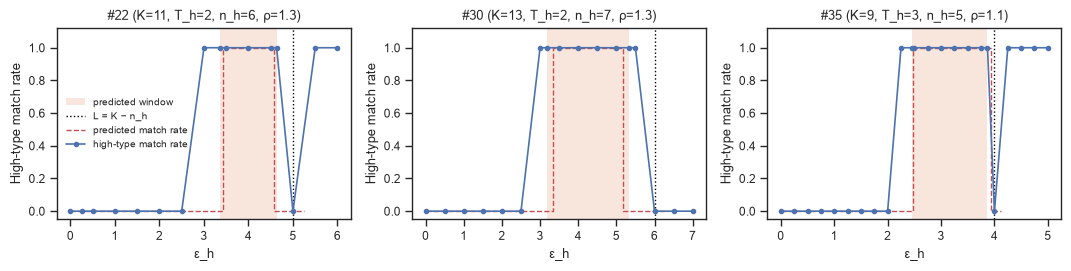

In [53]:
sns.set_theme(context="paper", style="ticks")

instance_ids = sorted(sweep["instance_id"].unique())
n_cols = min(3, len(instance_ids))
n_rows = int(np.ceil(len(instance_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 2.8 * n_rows), squeeze=False)

for ax, instance_id in zip(axes.flat, instance_ids):
    row = windows.loc[instance_id]
    d = sweep.query("instance_id == @instance_id")

    # predicted inefficient window in the unsaturated regime, clipped at L
    lo, hi = row["eps_h_minus"], min(row["eps_h_plus"], row["L"])
    if lo < hi:
        ax.axvspan(lo, hi, color=sns.color_palette()[1], alpha=0.2, linewidth=0, label="predicted window")
    ax.axvline(row["L"], color="black", linestyle=":", linewidth=1, label="L = K − n_h")

    ax.step(d["eps_h"], d["predicted_n_high"] / row["T_h"], where="mid", color=sns.color_palette()[3],
            linewidth=1, linestyle="--", label="predicted match rate")
    ax.plot(d["eps_h"], d["high_match_rate"], marker="o", markersize=3, color=sns.color_palette()[0],
            label="high-type match rate")

    ax.set_ylim(-0.05, 1.12)
    ax.set_xlabel("ε_h")
    ax.set_ylabel("High-type match rate")
    ax.set_title(f"#{instance_id} (K={row['K']}, T_h={row['T_h']}, n_h={row['n_h']}, ρ={row['rho']})")

for ax in axes.flat[len(instance_ids):]:
    ax.set_visible(False)

axes.flat[0].legend(frameon=False, fontsize=7, loc="center left")
plt.tight_layout()
plt.show()

## Refinement near the switches

Adds points at `REFINE_STEP` spacing in two places:
- **Observed switches**: between every pair of consecutive solved points where the number of matched high types changes, so each switch is located to within `REFINE_STEP`.
- **Predicted switches**: `REFINE_RADIUS` steps either side of `ε_h⁻`, `ε_h⁺`, and `L`, so we can see whether the solver switches at the predicted point even where the coarse grid shows no disagreement.

Points already in the cache are skipped (independently of `OVERWRITE`), and new results record the solver options they were solved with. Rerun the grid cell after a refinement pass to refine further.

In [54]:
REFINE_STEP = 0.1
REFINE_RADIUS = 1           # predicted-switch points: ±REFINE_RADIUS · REFINE_STEP around ε_h⁻, ε_h⁺, L
REFINE_OVERWRITE = False


def cached_points(instance_id: int) -> list[tuple[float, int]]:
    # (eps_h, number of high types matched) for every solved point of this instance
    points = []
    for path in (RESULTS_DIR / f"instance_{instance_id}").glob("*.json.gz"):
        with gzip.open(path, "rt", encoding="utf-8") as f:
            payload = json.load(f)
        primary = payload["summary"]["platform_solve_result"]["primary_result"]
        points.append((payload["eps_h"], len(set(primary["selected_intermediaries"]) & set(payload["high_ids"]))))
    return sorted(points)


def refinement_grid(instance_id: int) -> list[float]:
    row = windows.loc[instance_id]
    points = cached_points(instance_id)
    new = set()
    for (e1, k1), (e2, k2) in zip(points, points[1:]):
        if k1 != k2:
            new.update(np.arange(e1, e2, REFINE_STEP)[1:])
    for x in [row["eps_h_minus"], row["eps_h_plus"], row["L"]]:
        new.update(x + REFINE_STEP * np.arange(-REFINE_RADIUS, REFINE_RADIUS + 1))
    solved = {round(e, 6) for e, _ in points}
    return sorted({round(float(x), 6) for x in new if x >= 0} - solved)


refine_grids = {instance_id: refinement_grid(instance_id) for instance_id in INSTANCE_IDS}
for instance_id, grid in refine_grids.items():
    print(f"instance {instance_id}: {len(grid)} new points -> {grid}")
print(f"total: {sum(map(len, refine_grids.values()))} solves")

instance 22: 15 new points -> [2.6, 2.7, 2.8, 2.9, 3.267544, 3.467544, 4.532456, 4.732456, 4.832456, 4.9, 4.932456, 5.1, 5.2, 5.3, 5.4]
instance 30: 13 new points -> [2.6, 2.7, 2.8, 2.9, 3.071807, 3.271807, 5.228193, 5.428193, 5.6, 5.7, 5.8, 5.9, 6.1]
instance 35: 9 new points -> [2.1, 2.2, 2.363499, 2.563499, 3.769834, 3.9, 3.969834, 4.1, 4.2]
total: 37 solves


In [55]:
def solve_and_cache(instance_id: int, eps_hs: list[float], overwrite: bool) -> None:
    instance, high_ids, het_costs = built[instance_id]
    row = windows.loc[instance_id]
    optimizer = Optimizer(
        instance=instance,
        params=OptimizerParams(
            het_costs=het_costs,
            backend="gurobi",
            vrp_mode="approximate",
            vrp_time_limit_seconds=VRP_TIME_LIMIT_SECONDS,
            threads=SOLVER_THREADS,
            verbose=VERBOSE,
        ),
    )
    optimizer_seed = int(np.random.SeedSequence([BASE_SEED, instance_id, 1]).generate_state(1, dtype=np.uint32)[0])

    for eps_h in eps_hs:
        path = result_path(instance_id, eps_h)
        if path.exists() and not overwrite:
            continue

        epsilons = {
            i.id: eps_h if i.id in high_ids else float(row["eps_l"])
            for i in instance.intermediaries
        }
        start = time.time()
        summary = optimizer.solve(SolverOptions(**SOLVER_OPTIONS, seed=optimizer_seed), epsilons=epsilons)
        elapsed = time.time() - start

        result = summary.return_dict()
        matched = set(result["platform_solve_result"]["primary_result"]["selected_intermediaries"])
        print(f"instance {instance_id}, ε_h={eps_h:.3f}: {len(matched & high_ids)}/{len(high_ids)} "
              f"high types matched, {len(matched)} matched total ({elapsed:.0f}s)")

        path.parent.mkdir(parents=True, exist_ok=True)
        with gzip.open(path, "wt", encoding="utf-8") as f:
            json.dump({
                "instance_id": instance_id,
                "eps_h": eps_h,
                "high_ids": sorted(high_ids),
                "instances_csv": str(INSTANCES_CSV),
                "farmer_quantity": float(row["farmer_quantity"]),
                "sigma_ell": SIGMA_ELL,
                "base_seed": BASE_SEED,
                "optimizer_seed": optimizer_seed,
                "solver_options": SOLVER_OPTIONS,
                "summary": result,
            }, f)


for instance_id, grid in refine_grids.items():
    solve_and_cache(instance_id, grid, overwrite=REFINE_OVERWRITE)



============================= Optimizer Parameters =============================
---------------------------------- het_costs -----------------------------------
  {'brave_bhabha': 0.0,
   'brave_napier': 0.0,
   'competent_hellman': 0.0,
   'cranky_pike': 0.0,
   'determined_herschel': 240000.00000000003,
   'elastic_wing': 0.0,
   'eloquent_khayyam': 240000.00000000003,
   'frosty_chatelet': 0.0,
   'hardcore_knuth': 0.0,
   'musing_black': 0.0,
   'musing_lederberg': 0.0,
   'sad_murdock': 0.0,
   'serene_moser': 0.0,
   'thirsty_haibt': 0.0}
  backend                    gurobi
  vrp_mode                   approximate
  verbose                    True
  print_width                80
  threads                    12
  vrp_time_limit_seconds     300
  farmers                    24
  intermediaries             14


============================== VRP Initialization ==============================
---------------------- Solving for minimum cost matching -----------------------
Set parame

### Located switches vs. prediction

Each row is a pair of consecutive solved points where the number of matched high types changes: the switch lies in `(eps_h_before, eps_h_after]`. `nearest_prediction` is the closest of `ε_h⁻`, `ε_h⁺`, `L`, and `offset` is how far the bracket's midpoint sits from it (negative = the solver switches earlier than predicted).

In [56]:
switch_rows = []
for instance_id in INSTANCE_IDS:
    row = windows.loc[instance_id]
    predictions = {"ε_h⁻": row["eps_h_minus"], "ε_h⁺": row["eps_h_plus"], "L": row["L"]}
    points = cached_points(instance_id)
    for (e1, k1), (e2, k2) in zip(points, points[1:]):
        if k1 == k2:
            continue
        mid = (e1 + e2) / 2
        name, value = min(predictions.items(), key=lambda item: abs(item[1] - mid))
        switch_rows.append({
            "instance_id": instance_id,
            "eps_h_before": e1,
            "eps_h_after": e2,
            "n_high_before": k1,
            "n_high_after": k2,
            "nearest_prediction": name,
            "predicted_eps_h": value,
            "offset": mid - value,
        })

switches = pd.DataFrame(switch_rows)
switches

,instance_id,eps_h_before,eps_h_after,n_high_before,n_high_after,nearest_prediction,predicted_eps_h,offset
0,22,2.900000,3.000000,0,2,ε_h⁻,3.367544,-0.417544
1,22,4.932456,5.000000,2,0,L,5.000000,-0.033772
2,22,5.000000,5.100000,0,2,L,5.000000,0.050000
3,30,2.700000,2.800000,0,2,ε_h⁻,3.171807,-0.421807
4,30,5.600000,5.700000,2,0,ε_h⁺,5.328193,0.321807
5,35,2.100000,2.200000,0,1,ε_h⁻,2.463499,-0.313499
6,35,2.200000,2.250000,1,3,ε_h⁻,2.463499,-0.238499
7,35,3.900000,3.969834,3,0,ε_h⁺,3.869834,0.065083
8,35,4.000000,4.100000,0,3,L,4.000000,0.050000


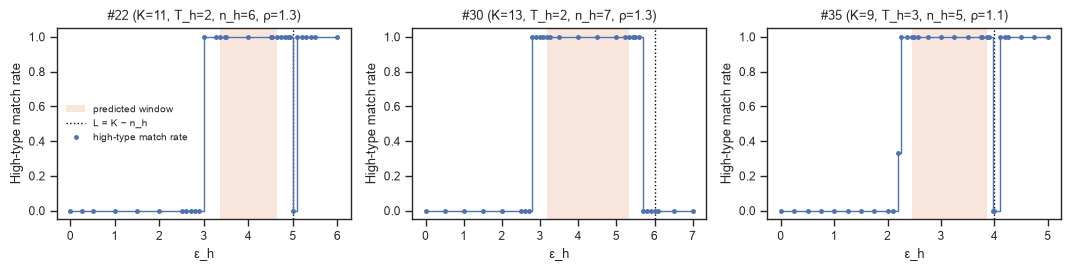

In [57]:
fig, axes = plt.subplots(1, len(INSTANCE_IDS), figsize=(3.6 * len(INSTANCE_IDS), 2.8), squeeze=False)

for ax, instance_id in zip(axes.flat, INSTANCE_IDS):
    row = windows.loc[instance_id]
    points = cached_points(instance_id)
    eps, n_high = zip(*points)

    lo, hi = row["eps_h_minus"], min(row["eps_h_plus"], row["L"])
    if lo < hi:
        ax.axvspan(lo, hi, color=sns.color_palette()[1], alpha=0.2, linewidth=0, label="predicted window")
    ax.axvline(row["L"], color="black", linestyle=":", linewidth=1, label="L = K − n_h")
    ax.step(eps, np.array(n_high) / row["T_h"], where="post", color=sns.color_palette()[0], linewidth=1)
    ax.plot(eps, np.array(n_high) / row["T_h"], "o", markersize=2.5, color=sns.color_palette()[0],
            label="high-type match rate")

    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("ε_h")
    ax.set_ylabel("High-type match rate")
    ax.set_title(f"#{instance_id} (K={row['K']}, T_h={row['T_h']}, n_h={row['n_h']}, ρ={row['rho']})")

axes.flat[0].legend(frameon=False, fontsize=7, loc="center left")
plt.tight_layout()
plt.show()